# Logistic Regression: Position Decoding

Predicts sequence position (1–5) of InSeq odor trials with logistic regression, and compares two inputs:

- **Raw LFP:** the preprocessed 500 ms LFP windows
- **Latent LFP:** the CEBRA latents of the same trials

One model per rat. The regularization strength is chosen on the validation split, and the test split is used only for the final scores.
Scores are balanced accuracy; chance is 20% for five positions.

**Input:** `data/processed/raw_lfp/` and `data/processed/cebra_latents/`

## Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110

## Paths

In [2]:
# Repository root: the first folder above this notebook that contains pyproject.toml
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())

RAW_ROOT    = REPO / 'data' / 'processed' / 'raw_lfp'
LATENT_ROOT = REPO / 'data' / 'processed' / 'cebra_latents'

SESSIONS = sorted(p.name for p in LATENT_ROOT.iterdir() if (p / 'cebra_latents.npz').is_file())
print('Rats:', SESSIONS)

Rats: ['080718_mitt', '081106_barat', '090212_stella', '090212_superchris', '090420_buchanan']


## Load data

Raw LFP and latents for each rat, with position labels and the train / validation / test split. The table shows how many trials of each position are in each split.

In [3]:
def load_session(session):
    """Raw LFP, CEBRA latents and position labels for one rat, checked to be in the same trial order."""
    with np.load(RAW_ROOT / session / 'position_decoding.npz') as raw, \
         np.load(LATENT_ROOT / session / 'cebra_latents.npz') as lat:
        assert np.array_equal(raw['trial_ids'], lat['trial_ids']), f'{session}: trial order differs'
        assert np.array_equal(raw['split'], lat['split']), f'{session}: splits differ'
        return dict(raw=raw['X'], latent=lat['Z'], y=raw['y'],
                    split=raw['split'].astype(str), trial_ids=raw['trial_ids'])


data = {session: load_session(session) for session in SESSIONS}

rows = []
for session, d in data.items():
    for split in ('train', 'validation', 'test'):
        counts = np.bincount(d['y'][d['split'] == split], minlength=5)
        rows.append(dict(rat=session, split=split, trials=counts.sum(),
                         **{f'pos {p + 1}': c for p, c in enumerate(counts)}))
display(pd.DataFrame(rows).set_index(['rat', 'split']))
print({s: (d['raw'].shape, d['latent'].shape) for s, d in data.items()})

trials  pos 1  pos 2  pos 3  pos 4  pos 5
rat               split                                                
080718_mitt       train          167     47     37     31     30     22
                  validation      47     16     11      8      8      4
                  test            35     11     10      8      3      3
081106_barat      train          111     34     25     19     19     14
                  validation      24      7      7      3      4      3
                  test            19      8      2      3      3      3
090212_stella     train          150     46     36     25     22     21
                  validation      28      7      5      7      6      3
                  test            12      4      4      1      2      1
090212_superchris train          138     42     34     24     23     15
                  validation      31      8      7      6      5      5
                  test            18      5      3      4      2      4
090420_buchanan   train          174     54     34     22     36     28
                  validation      19      4      5      3      5      2
                  test            15      6      3      3      2      1

{'080718_mitt': ((249, 500, 22), (249, 500, 8)), '081106_barat': ((154, 500, 22), (154, 500, 8)), '090212_stella': ((190, 500, 21), (190, 500, 8)), '090212_superchris': ((187, 500, 21), (187, 500, 8)), '090420_buchanan': ((208, 500, 20), (208, 500, 8))}


## Features

Each trial is averaged into 50 ms time bins, the same way for raw LFP and latents, then flattened into one feature vector:
- **Raw:** 10 bins × channels
- **Latent:** 10 bins × 8 latent dimensions

**Why 50 ms bins:** using every sample would give 11,000 raw features for only 111–174 training trials per rat. Ten 50 ms bins keep how the signal changes over time while reducing that to about 200 features.
Using the same binning for both inputs makes the raw vs latent comparison fair.

In [4]:
BIN_MS = 50   # width of each time bin (samples are 1 ms)


def bin_features(A, bin_ms=BIN_MS):
    """trials x samples x channels -> trials x (bins * channels), averaging within each time bin."""
    trials, samples, channels = A.shape
    assert samples % bin_ms == 0, f'{samples} samples do not split into {bin_ms} ms bins'
    binned = A.reshape(trials, samples // bin_ms, bin_ms, channels).mean(axis=2)
    return binned.reshape(trials, -1)


features = {session: {'raw': bin_features(d['raw']), 'latent': bin_features(d['latent'])}
            for session, d in data.items()}
display(pd.DataFrame({s: {name: f.shape for name, f in fs.items()} for s, fs in features.items()}).T)

,raw,latent
080718_mitt,"(249, 220)","(249, 80)"
081106_barat,"(154, 220)","(154, 80)"
090212_stella,"(190, 210)","(190, 80)"
090212_superchris,"(187, 210)","(187, 80)"
090420_buchanan,"(208, 200)","(208, 80)"


## Fit models

For each rat and each input, a logistic regression is fitted on the training trials for each regularization strength `C`.
The `C` with the best validation balanced accuracy is kept.

- **Why a range of `C` (0.001 to 10):** `C` controls how strongly the model is kept simple. Values spaced by factors of 10 cover strong to weak regularization; the validation split picks one, so the test split is never used for tuning.
- **Why ties go to the smaller `C`:** when two values score the same, the simpler model is less likely to be fitting noise.
- **Why standardize features:** the latents are not on a common scale. The scaler is fitted on training trials only.
- **Why `class_weight='balanced'`:** position 1 has the most trials. Weighting stops the model from scoring well by mostly guessing position 1.
- **Why balanced accuracy:** the average of the per-position accuracies, so every position counts equally. Chance is 20% for five positions.
- **Why `max_iter=5000`:** enough steps for the fit to converge with 200+ features.

In [5]:
import warnings
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

warnings.filterwarnings('ignore', message='y_pred contains classes not in y_true')

C_GRID = [0.001, 0.01, 0.1, 1, 10]   # smaller C = stronger regularization


def make_model(C):
    """Scaler and L2-regularized logistic regression; both are fitted on training trials only."""
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=C, class_weight='balanced', max_iter=5000))


def fit_with_validation(F, y, split):
    """Fit one model per C on train, keep the C with the best validation balanced accuracy.

    Ties go to the smaller C. The test split is not touched here.
    """
    train, val = split == 'train', split == 'validation'
    best = None
    for C in C_GRID:
        model = make_model(C).fit(F[train], y[train])
        score = balanced_accuracy_score(y[val], model.predict(F[val]))
        if best is None or score > best['val_score']:
            best = dict(C=C, val_score=score, model=model)
    return best


fits, rows = {}, []
for session, d in data.items():
    for name in ('raw', 'latent'):
        best = fit_with_validation(features[session][name], d['y'], d['split'])
        fits[session, name] = best
        rows.append(dict(rat=session, input=name, chosen_C=best['C'], validation_bal_acc=best['val_score']))

display(pd.DataFrame(rows).pivot(index='rat', columns='input', values=['chosen_C', 'validation_bal_acc']).round(3))

chosen_C         validation_bal_acc       
input               latent     raw             latent    raw
rat                                                         
080718_mitt            0.1   0.100              0.236  0.315
081106_barat          10.0   0.100              0.402  0.295
090212_stella          0.1  10.000              0.311  0.590
090212_superchris      0.1   0.001              0.435  0.354
090420_buchanan        1.0  10.000              0.250  0.320

## Test results

Each chosen model is scored once on the test split. For comparison, the same model is refitted 50 times on shuffled training labels; a real score should sit above the 95th percentile of those shuffled scores.

**Why a shuffled baseline as well as 20% chance:** with test sets of 12–35 trials, a model with no real information can still score 30–50% by luck.
The shuffled scores show how high luck alone reaches for each rat. Fifty shuffles give a rough 95th percentile while keeping the run short.

In [6]:
N_SHUFFLES = 50
rng = np.random.default_rng(0)

results = []
for session, d in data.items():
    train, test = d['split'] == 'train', d['split'] == 'test'
    y = d['y']
    for name in ('raw', 'latent'):
        F, fit = features[session][name], fits[session, name]
        pred = fit['model'].predict(F[test])
        # Same model and C, refitted on shuffled training labels: the score a model gets by chance
        shuffled = [balanced_accuracy_score(y[test], make_model(fit['C']).fit(F[train], rng.permutation(y[train])).predict(F[test]))
                    for _ in range(N_SHUFFLES)]
        results.append(dict(rat=session, input=name, test_trials=int(test.sum()), chosen_C=fit['C'],
                            test_bal_acc=balanced_accuracy_score(y[test], pred),
                            shuffle_mean=np.mean(shuffled), shuffle_95th=np.percentile(shuffled, 95),
                            pred=pred))

results_df = pd.DataFrame(results).drop(columns='pred')
display(results_df.round(3))
display(results_df.pivot(index='rat', columns='input', values='test_bal_acc').agg(['mean', 'std']).round(3))

,rat,input,test_trials,chosen_C,test_bal_acc,shuffle_mean,shuffle_95th
0,080718_mitt,raw,35,0.100,0.358,0.227,0.360
1,080718_mitt,latent,35,0.100,0.193,0.196,0.311
2,081106_barat,raw,19,0.100,0.475,0.206,0.358
3,081106_barat,latent,19,10.000,0.267,0.204,0.388
4,090212_stella,raw,12,10.000,0.350,0.179,0.350
5,090212_stella,latent,12,0.100,0.400,0.199,0.500
6,090212_superchris,raw,18,0.001,0.387,0.217,0.382
7,090212_superchris,latent,18,0.100,0.350,0.191,0.338
8,090420_buchanan,raw,15,10.000,0.467,0.222,0.418
9,090420_buchanan,latent,15,1.000,0.300,0.207,0.518


input,latent,raw
mean,0.302,0.407
std,0.079,0.060


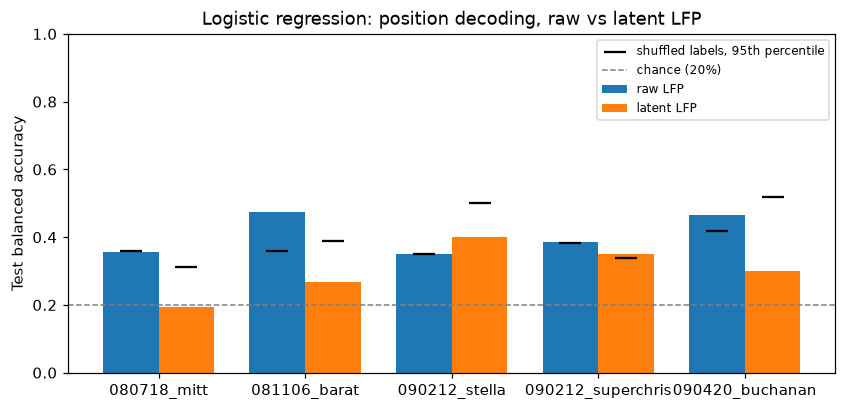

In [7]:
table = results_df.pivot(index='rat', columns='input', values='test_bal_acc')[['raw', 'latent']]
shuffle = results_df.pivot(index='rat', columns='input', values='shuffle_95th')[['raw', 'latent']]

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(table))
for i, name in enumerate(['raw', 'latent']):
    ax.bar(x + (i - .5) * .38, table[name], width=.38, label=f'{name} LFP')
    ax.scatter(x + (i - .5) * .38, shuffle[name], color='k', marker='_', s=200, zorder=3,
               label='shuffled labels, 95th percentile' if i == 0 else None)
ax.axhline(.2, color='gray', ls='--', lw=1, label='chance (20%)')
ax.set(xticks=x, xticklabels=table.index, ylim=(0, 1), ylabel='Test balanced accuracy',
       title='Logistic regression: position decoding, raw vs latent LFP')
ax.legend(fontsize=8)
plt.show()

Confusion matrices on the test split: rows are the true position, columns the predicted position. A strong diagonal means correct predictions.

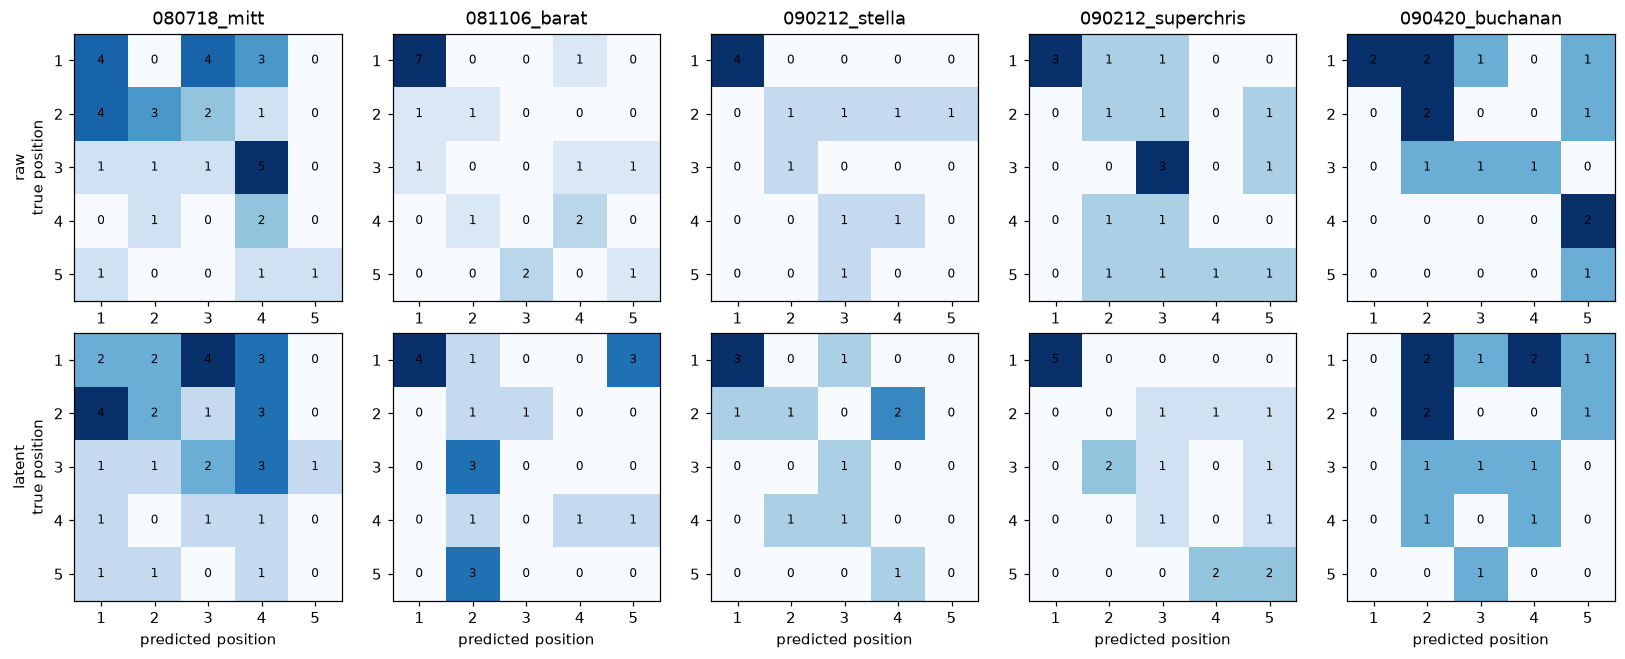

In [8]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, len(SESSIONS), figsize=(3 * len(SESSIONS), 6), squeeze=False)
for col, session in enumerate(SESSIONS):
    y_test = data[session]['y'][data[session]['split'] == 'test']
    for row, name in enumerate(['raw', 'latent']):
        pred = next(r['pred'] for r in results if r['rat'] == session and r['input'] == name)
        cm = confusion_matrix(y_test, pred, labels=range(5))
        ax = axes[row, col]
        ax.imshow(cm, cmap='Blues')
        for i in range(5):
            for j in range(5):
                ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8)
        ax.set(xticks=range(5), xticklabels=range(1, 6), yticks=range(5), yticklabels=range(1, 6),
               title=session if row == 0 else '')
        if col == 0:
            ax.set_ylabel(f'{name}\ntrue position')
        if row == 1:
            ax.set_xlabel('predicted position')
plt.tight_layout()
plt.show()

## Summary

Raw LFP decodes position modestly above chance; the CEBRA latents mostly do not.

| Rat | Test trials | Raw | Shuffled 95th | Latent | Shuffled 95th |
|---|---|---|---|---|---|
| Mitt | 35 | 35.8% | 36.0% | 19.3% | 31.1% |
| Barat | 19 | 47.5% | 35.8% | 26.7% | 38.8% |
| Stella | 12 | 35.0% | 35.0% | 40.0% | 50.0% |
| Superchris | 18 | 38.7% | 38.2% | 35.0% | 33.8% |
| Buchanan | 15 | 46.7% | 41.8% | 30.0% | 51.8% |
| Mean ± SD | – | 40.7% ± 6.0 | – | 30.2% ± 7.9 | – |

Test balanced accuracy; chance is 20%.

**Raw LFP**
- Above chance in every rat and better than the latents in 4 of 5 rats.
- Clearly above the shuffled-label baseline in Barat and Buchanan, barely in Superchris, and level with it in Mitt and Stella.

**Latent LFP**
- Above the shuffled baseline only in Superchris, and only barely. In the other 4 rats it is within chance range, so these latents do not carry usable position information for a linear model.
- Stella's latent score (40%) rests on 12 test trials, where the shuffled 95th percentile is 50%.

**Confusion matrices:** most correct predictions are position 1; positions 2–5 are largely confused with each other.
Position 1 is always odor A on InSeq trials, so this may reflect odor as much as position.

**Caveats**
- Very small test sets (12–35 trials, some positions with 1–3), so one trial moves a score by several points.
- The chosen `C` varies widely across rats (0.001 to 10), because the validation sets are too small to choose it reliably.
- One train / validation / test split and one CEBRA seed; CEBRA training loss was still decreasing at 1,000 updates.

**Next steps**
1. kNN with the same features and splits.
2. Odor decoding as a benchmark, using `odor_decoding.npz`.
3. The 250–500 ms window (a slice of the current data).
4. Longer CEBRA training, choosing the number of updates on the validation split.

## 250–500 ms window

Repeats the same models using only 250–500 ms after odor onset, to check whether position information is clearer later in the window.

- **Why this window:** the first few hundred milliseconds after odor onset contain a strong response that looks similar for every position. Dropping it may leave a cleaner position signal.
- **Why no new preprocessing:** 250–500 ms lies inside the saved 0–500 ms windows, so it is a slice of the same data, with the same scaling and splits.
- **Latents:** sliced from the same CEBRA latents; CEBRA is not retrained for this window.
- **Features:** the same 50 ms bins, so 5 bins instead of 10. `C` is chosen again on the validation split for this window.

In [9]:
WINDOW_MS = (250, 500)   # start and end, in ms after odor onset (samples are 1 ms)

rng = np.random.default_rng(0)   # same seed as the 0-500 ms shuffles
window_results = []
for session, d in data.items():
    start, end = WINDOW_MS
    window_features = {'raw': bin_features(d['raw'][:, start:end]),
                       'latent': bin_features(d['latent'][:, start:end])}
    train, test, y = d['split'] == 'train', d['split'] == 'test', d['y']
    for name, F in window_features.items():
        fit = fit_with_validation(F, y, d['split'])      # C chosen on validation, as before
        pred = fit['model'].predict(F[test])
        shuffled = [balanced_accuracy_score(y[test], make_model(fit['C']).fit(F[train], rng.permutation(y[train])).predict(F[test]))
                    for _ in range(N_SHUFFLES)]
        window_results.append(dict(rat=session, input=name, n_features=F.shape[1], chosen_C=fit['C'],
                                   validation_bal_acc=fit['val_score'],
                                   test_bal_acc=balanced_accuracy_score(y[test], pred),
                                   shuffle_95th=np.percentile(shuffled, 95)))

window_df = pd.DataFrame(window_results)
display(window_df.round(3))

,rat,input,n_features,chosen_C,validation_bal_acc,test_bal_acc,shuffle_95th
0,080718_mitt,raw,110,0.10,0.223,0.248,0.355
1,080718_mitt,latent,40,10.00,0.167,0.121,0.330
2,081106_barat,raw,110,1.00,0.390,0.250,0.330
3,081106_barat,latent,40,0.01,0.295,0.283,0.317
4,090212_stella,raw,105,10.00,0.444,0.200,0.400
5,090212_stella,latent,40,0.01,0.323,0.400,0.350
6,090212_superchris,raw,105,10.00,0.456,0.260,0.357
7,090212_superchris,latent,40,1.00,0.529,0.310,0.357
8,090420_buchanan,raw,100,0.10,0.280,0.233,0.367
9,090420_buchanan,latent,40,0.10,0.147,0.400,0.385


Test balanced accuracy for both windows, side by side. A real improvement should also sit above that window's shuffled 95th percentile.

In [10]:
label = f'{WINDOW_MS[0]}-{WINDOW_MS[1]} ms'
full = results_df.pivot(index='rat', columns='input', values='test_bal_acc')
late = window_df.pivot(index='rat', columns='input', values='test_bal_acc')
late_shuffle = window_df.pivot(index='rat', columns='input', values='shuffle_95th')

comparison = pd.DataFrame({
    'raw 0-500 ms': full['raw'], f'raw {label}': late['raw'], f'raw {label} shuffled 95th': late_shuffle['raw'],
    'latent 0-500 ms': full['latent'], f'latent {label}': late['latent'],
    f'latent {label} shuffled 95th': late_shuffle['latent'],
})
comparison.loc['mean'] = comparison.mean()
display(comparison.round(3))

,raw 0-500 ms,raw 250-500 ms,raw 250-500 ms shuffled 95th,latent 0-500 ms,latent 250-500 ms,latent 250-500 ms shuffled 95th
rat,,,,,,
080718_mitt,0.358,0.248,0.355,0.193,0.121,0.330
081106_barat,0.475,0.250,0.330,0.267,0.283,0.317
090212_stella,0.350,0.200,0.400,0.400,0.400,0.350
090212_superchris,0.387,0.260,0.357,0.350,0.310,0.357
090420_buchanan,0.467,0.233,0.367,0.300,0.400,0.385
mean,0.407,0.238,0.361,0.302,0.303,0.348


### 250–500 ms window: summary

Removing the first 250 ms after odor onset removes almost all of the raw LFP's position information.

| Rat | Raw 0–500 | Raw 250–500 | Shuffled 95th | Latent 0–500 | Latent 250–500 | Shuffled 95th |
|---|---|---|---|---|---|---|
| Mitt | 35.8% | 24.8% | 35.5% | 19.3% | 12.1% | 33.0% |
| Barat | 47.5% | 25.0% | 33.0% | 26.7% | 28.3% | 31.7% |
| Stella | 35.0% | 20.0% | 40.0% | 40.0% | 40.0% | 35.0% |
| Superchris | 38.7% | 26.0% | 35.7% | 35.0% | 31.0% | 35.7% |
| Buchanan | 46.7% | 23.3% | 36.7% | 30.0% | 40.0% | 38.5% |
| Mean | 40.7% | 23.8% | 36.1% | 30.2% | 30.3% | 34.8% |

Shuffled 95th percentiles are for the 250–500 ms window.

**Raw LFP:** drops from 40.7% to 23.8%, below the shuffled baseline in every rat. The 0–500 ms raw results therefore come from the first 250 ms, the early response to odor onset.
That early response is also where position 1 stands out, and position 1 is always odor A on InSeq trials, so the most likely source is the response to the odor itself rather than a separate position signal.

**Latent LFP:** unchanged on average (30.2% → 30.3%). Above the shuffled baseline only in Stella and, barely, Buchanan, with 12 and 15 test trials, which is not enough to claim a real effect.

**Caveats:** this window has half the features (5 bins instead of 10), and test sets are still 12–35 trials, so differences between individual rats mean little. The raw drop seen in all 5 rats is the reliable result.

**Next steps**
1. Odor decoding with the same models, as a benchmark: if odor decodes as well as position, and also only from the early window, that points toward odor rather than position.
2. A sliding-window analysis (for example 100 ms steps) to show when in the 500 ms the information appears.